# Lab Problem 9 : Objective: Compare Linear and RBF SVM models using accuracy and decision boundary visualization.

Task 1: Data Preparation

In [1]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Step 1: Generate the two-moons dataset
X, y = make_moons(
    n_samples=200,
    noise=0.15,
    random_state=42
)

# Step 2: Split the dataset into training and testing sets (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 4: Display dataset information
print("Original dataset shape:", X.shape)
print("Training dataset shape:", X_train_scaled.shape)
print("Testing dataset shape:", X_test_scaled.shape)

print("\nTraining class counts [class 0, class 1]:",
      np.bincount(y_train))
print("Testing class counts [class 0, class 1]:",
      np.bincount(y_test))

print("\nMean of scaled training features:",
      X_train_scaled.mean(axis=0).round(3))
print("Standard deviation of scaled training features:",
      X_train_scaled.std(axis=0).round(3))

Original dataset shape: (200, 2)
Training dataset shape: (160, 2)
Testing dataset shape: (40, 2)

Training class counts [class 0, class 1]: [80 80]
Testing class counts [class 0, class 1]: [20 20]

Mean of scaled training features: [-0.  0.]
Standard deviation of scaled training features: [1. 1.]


Task 2 — SVM Model Training

In [2]:
from sklearn.svm import SVC

# Model 1: Linear SVM
linear_svm = SVC(kernel="linear", C=1.0)

# Model 2: RBF SVM - Model A
rbf_model_a = SVC(kernel="rbf", C=0.1, gamma=0.1)

# Model 3: RBF SVM - Model B
rbf_model_b = SVC(kernel="rbf", C=1.0, gamma=1.0)

# Model 4: RBF SVM - Model C
rbf_model_c = SVC(kernel="rbf", C=10.0, gamma=10.0)

# Train all models using the training dataset
linear_svm.fit(X_train_scaled, y_train)
rbf_model_a.fit(X_train_scaled, y_train)
rbf_model_b.fit(X_train_scaled, y_train)
rbf_model_c.fit(X_train_scaled, y_train)

# Store the trained models for use in later tasks
models = {
    "Linear SVM": linear_svm,
    "RBF Model A": rbf_model_a,
    "RBF Model B": rbf_model_b,
    "RBF Model C": rbf_model_c
}

print("All four SVM models have been trained successfully.")

for name, model in models.items():
    print(f"{name}: {model.kernel} kernel, C={model.C}, gamma={model.gamma}")

All four SVM models have been trained successfully.
Linear SVM: linear kernel, C=1.0, gamma=scale
RBF Model A: rbf kernel, C=0.1, gamma=0.1
RBF Model B: rbf kernel, C=1.0, gamma=1.0
RBF Model C: rbf kernel, C=10.0, gamma=10.0


Task 3 — Evaluation of SVM Models

In [3]:
from sklearn.metrics import accuracy_score
import pandas as pd

# Store accuracy scores and predictions for later tasks
accuracy_results = {}
prediction_results = {}
results = []

# Evaluate all four trained models
for name, model in models.items():

    # Predict the classes of the test samples
    y_pred = model.predict(X_test_scaled)

    # Calculate test accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Store results for future tasks
    accuracy_results[name] = accuracy
    prediction_results[name] = y_pred

    # Prepare one row for the comparison table
    gamma_value = model.gamma if model.kernel == "rbf" else "N/A"

    results.append({
        "Model": name,
        "Kernel": model.kernel,
        "C": model.C,
        "Gamma": gamma_value,
        "Test Accuracy": accuracy,
        "Accuracy (%)": accuracy * 100
    })

# Create an organized results table
accuracy_table = pd.DataFrame(results)

print("TEST ACCURACY COMPARISON")
print("=" * 75)

print(
    accuracy_table.to_string(
        index=False,
        formatters={
            "C": lambda value: f"{value:.1f}",
            "Test Accuracy": lambda value: f"{value:.4f}",
            "Accuracy (%)": lambda value: f"{value:.2f}%"
        }
    )
)

# Compare each RBF model with the Linear SVM
linear_accuracy = accuracy_results["Linear SVM"]

print("\nCOMPARISON WITH LINEAR SVM")
print("=" * 75)

for name in ["RBF Model A", "RBF Model B", "RBF Model C"]:

    rbf_accuracy = accuracy_results[name]

    # Difference expressed in percentage points
    difference = (rbf_accuracy - linear_accuracy) * 100

    if difference > 0:
        print(
            f"{name} performs better than Linear SVM "
            f"by {difference:.2f} percentage points."
        )
    elif difference < 0:
        print(
            f"{name} performs worse than Linear SVM "
            f"by {abs(difference):.2f} percentage points."
        )
    else:
        print(f"{name} and Linear SVM have equal test accuracy.")

# Identify the best-performing model on this test set
best_model_name = max(accuracy_results, key=accuracy_results.get)

print(f"\nBest test accuracy: {best_model_name}")
print(f"Accuracy: {accuracy_results[best_model_name] * 100:.2f}%")

TEST ACCURACY COMPARISON
      Model Kernel    C Gamma Test Accuracy Accuracy (%)
 Linear SVM linear  1.0   N/A        0.9000       90.00%
RBF Model A    rbf  0.1   0.1        0.9250       92.50%
RBF Model B    rbf  1.0   1.0        0.9750       97.50%
RBF Model C    rbf 10.0  10.0        0.9750       97.50%

COMPARISON WITH LINEAR SVM
RBF Model A performs better than Linear SVM by 2.50 percentage points.
RBF Model B performs better than Linear SVM by 7.50 percentage points.
RBF Model C performs better than Linear SVM by 7.50 percentage points.

Best test accuracy: RBF Model B
Accuracy: 97.50%


Task 4 — Visualization of SVM Models

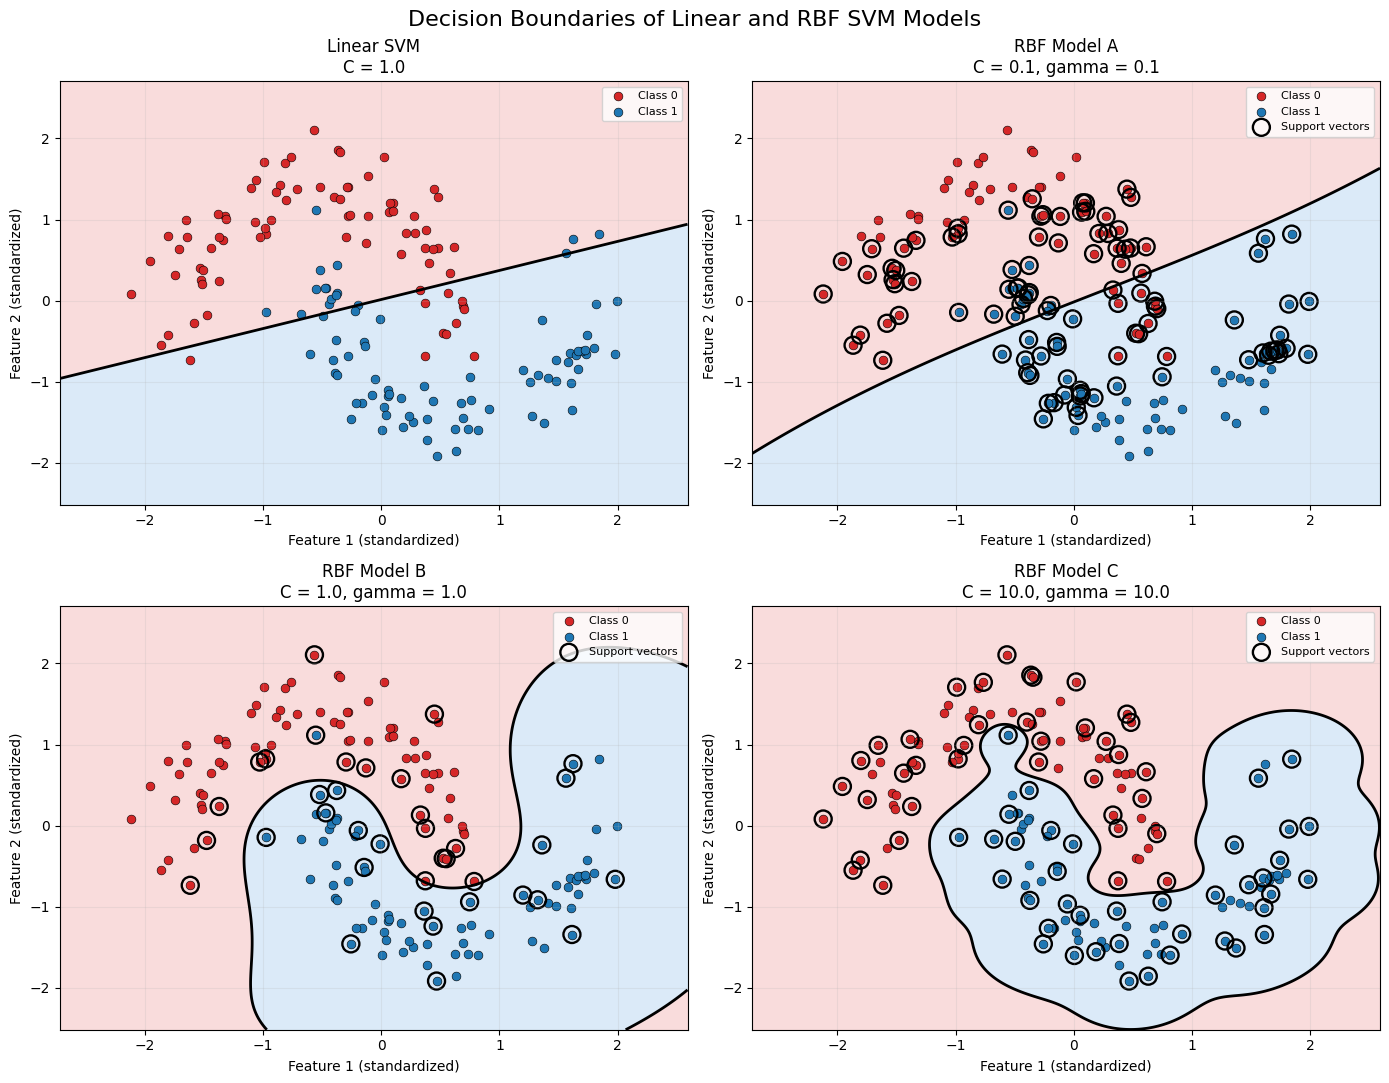

SUPPORT VECTOR SUMMARY
-------------------------------------------------------
RBF Model A: Class 0 = 53, Class 1 = 53, Total = 106
RBF Model B: Class 0 = 17, Class 1 = 20, Total = 37
RBF Model C: Class 0 = 38, Class 1 = 39, Total = 77


In [4]:
# Task 4A: Decision Boundaries and Support Vectors

import numpy as np
import matplotlib.pyplot as plt

# Models to visualize
model_names = [
    "Linear SVM",
    "RBF Model A",
    "RBF Model B",
    "RBF Model C"
]

# Create a grid covering the training data
x_min, x_max = X_train_scaled[:, 0].min() - 0.6, X_train_scaled[:, 0].max() + 0.6
y_min, y_max = X_train_scaled[:, 1].min() - 0.6, X_train_scaled[:, 1].max() + 0.6

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

# Combine grid coordinates into input samples
grid = np.c_[xx.ravel(), yy.ravel()]

# Create a 2 x 2 visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for ax, name in zip(axes, model_names):

    model = models[name]

    # Predict the class in each region of the grid
    regions = model.predict(grid).reshape(xx.shape)

    # Shade the predicted class regions
    ax.contourf(
        xx, yy, regions,
        levels=[-0.5, 0.5, 1.5],
        colors=["#F6CACA", "#C9DFF5"],
        alpha=0.65
    )

    # Calculate the decision function and draw the boundary
    decision_scores = model.decision_function(grid).reshape(xx.shape)

    ax.contour(
        xx, yy, decision_scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    # Plot training samples of class 0
    ax.scatter(
        X_train_scaled[y_train == 0, 0],
        X_train_scaled[y_train == 0, 1],
        color="#D62728",
        edgecolors="black",
        linewidths=0.4,
        s=40,
        label="Class 0"
    )

    # Plot training samples of class 1
    ax.scatter(
        X_train_scaled[y_train == 1, 0],
        X_train_scaled[y_train == 1, 1],
        color="#1F77B4",
        edgecolors="black",
        linewidths=0.4,
        s=40,
        label="Class 1"
    )

    # Highlight support vectors for the RBF models
    if model.kernel == "rbf":

        support_vectors = model.support_vectors_

        ax.scatter(
            support_vectors[:, 0],
            support_vectors[:, 1],
            s=150,
            facecolors="none",
            edgecolors="black",
            linewidths=1.7,
            label="Support vectors"
        )

    # Add title and axis labels
    ax.set_title(
        f"{name}\nC = {model.C}, gamma = {model.gamma}"
        if model.kernel == "rbf"
        else f"{name}\nC = {model.C}"
    )

    ax.set_xlabel("Feature 1 (standardized)")
    ax.set_ylabel("Feature 2 (standardized)")
    ax.legend(loc="best", fontsize=8)
    ax.grid(alpha=0.2)

plt.suptitle(
    "Decision Boundaries of Linear and RBF SVM Models",
    fontsize=16
)
plt.tight_layout()
plt.show()

# Report the support vector counts for each RBF model
print("SUPPORT VECTOR SUMMARY")
print("-" * 55)

for name in model_names[1:]:
    model = models[name]
    counts = model.n_support_

    print(
        f"{name}: Class 0 = {counts[0]}, "
        f"Class 1 = {counts[1]}, "
        f"Total = {counts.sum()}"
    )

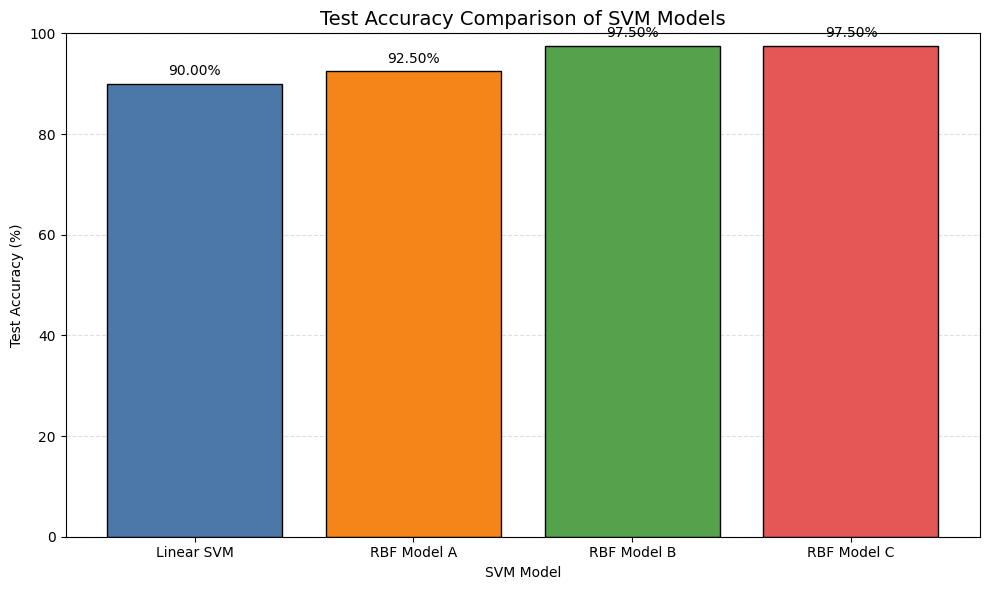

TEST ACCURACY RESULTS
-----------------------------------
Linear SVM     : 90.00%
RBF Model A    : 92.50%
RBF Model B    : 97.50%
RBF Model C    : 97.50%


In [5]:
# Task 4B: Test Accuracy Comparison Bar Chart

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Calculate test accuracy for all four models
model_names = list(models.keys())

accuracies = [
    accuracy_score(
        y_test,
        models[name].predict(X_test_scaled)
    ) * 100
    for name in model_names
]

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    model_names,
    accuracies,
    color=["#4C78A8", "#F58518", "#54A24B", "#E45756"],
    edgecolor="black"
)

# Add accuracy values above each bar
ax.bar_label(
    bars,
    labels=[f"{value:.2f}%" for value in accuracies],
    padding=4,
    fontsize=10
)

# Format the chart
ax.set_title("Test Accuracy Comparison of SVM Models", fontsize=14)
ax.set_xlabel("SVM Model")
ax.set_ylabel("Test Accuracy (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Print the numerical comparison
print("TEST ACCURACY RESULTS")
print("-" * 35)

for name, accuracy in zip(model_names, accuracies):
    print(f"{name:15s}: {accuracy:.2f}%")